# TPS · Módulo 4 — Sensibilidad metodológica de los resultados
**PSIB 2026Q2 · Grupo 12** · *Caracterización de la carga cognitiva mediante análisis espectral del EEG durante aritmética mental*

**Objetivo:** evaluar la influencia del estimador de PSD y del filtrado adicional sobre los cambios espectrales entre **tarea y reposo**, utilizando Welch sin filtrado adicional como referencia. Se comparan periodograma, Blackman–Tukey y AR (Yule–Walker y AIC), y tres alternativas de filtrado: sin filtrado adicional, FIR Kaiser e IIR Butterworth. Se repiten las pruebas regionales del Módulo 3 sin pseudorreplicar épocas ni canales.

**Entradas:** `modulo1_epocas.npz`, `modulo1_sujetos.csv` y `modulo2_potencias.csv`. Opcionales: `modulo3_wilcoxon_regiones.csv` y `modulo3_mannwhitney.csv`. No se requieren los archivos EDF.

**Criterios de comparación:**
- Se reproduce la exclusión exploratoria de épocas marcadas de los Módulos 2–3 y se contrasta con su inclusión; estas marcas no constituyen una validación de artefactos.
- Se conserva el denominador de potencia relativa **0,5–30 Hz** para la comparación con el Módulo 3 y se evalúa también **0,5–45 Hz**, intervalo establecido en el anteproyecto.
- Se emplea una observación por sujeto y región para Wilcoxon y Mann–Whitney, con FDR por familias de 50 pruebas para cada alternativa. Las comparaciones entre alternativas son análisis exploratorios de sensibilidad.

Las conclusiones cuantitativas deben interpretarse a partir de la ejecución con los registros reales.

## 0. Cargar y validar archivos

En Google Colab, ejecutar esta celda y seleccionar los tres archivos obligatorios. La carga de archivos es opcional si ya están en el directorio de trabajo. Se comprueban frecuencia de muestreo, canales, dimensiones, condiciones, etiquetas y correspondencia entre sujetos antes de calcular estadísticas.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal, stats
from statsmodels.stats.multitest import multipletests
from IPython.display import display

OBLIGATORIOS = ['modulo1_epocas.npz', 'modulo1_sujetos.csv', 'modulo2_potencias.csv']
OPCIONALES = ['modulo3_wilcoxon_regiones.csv', 'modulo3_mannwhitney.csv']
faltantes = [f for f in OBLIGATORIOS if not Path(f).is_file()]
if faltantes:
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError('Faltan archivos: ' + ', '.join(faltantes) + '. Copiarlos al directorio de trabajo.')
    print('Seleccionar archivos obligatorios:', ', '.join(faltantes))
    files.upload()
faltantes = [f for f in OBLIGATORIOS if not Path(f).is_file()]
if faltantes:
    raise FileNotFoundError('No se recibieron los siguientes archivos: ' + ', '.join(faltantes))

mod1 = np.load('modulo1_epocas.npz', allow_pickle=False)
info = pd.read_csv('modulo1_sujetos.csv')
pot_ref = pd.read_csv('modulo2_potencias.csv')
CANALES = [str(c) for c in mod1['canales']]
FS = float(mod1['fs'])
BANDAS = {'delta': (0.5, 4), 'theta': (4, 8), 'alfa': (8, 13), 'beta': (13, 30)}
REGIONES = {'frontal': ['Fp1','Fp2','F3','F4','F7','F8','Fz'],
            'central': ['C3','C4','Cz'], 'temporal': ['T3','T4','T5','T6'],
            'parietal': ['P3','P4','Pz'], 'occipital': ['O1','O2']}
REGION_DE = {c: r for r, cs in REGIONES.items() for c in cs}
CONDICIONES = ('reposo', 'tarea')
SUJETOS = info['Subject'].astype(str).tolist()
assert len(SUJETOS) == len(set(SUJETOS)) == 36, 'Se requieren 36 sujetos únicos.'
assert set(info['grupo']) == {'G', 'B'}, 'Grupos G/B ausentes.'
assert len(CANALES) == 19 and set(CANALES) == set(REGION_DE), 'Montaje incompatible.'
assert np.isclose(FS, 500), 'Se esperaba fs = 500 Hz.'
assert set(pot_ref.columns) >= {'sujeto','condicion','canal','banda','potencia'}, 'CSV del Módulo 2 incompatible.'
assert set(pot_ref.sujeto.astype(str)) == set(SUJETOS), 'Sujetos de potencias y épocas diferentes.'
assert set(pot_ref.condicion) == set(CONDICIONES), 'Condiciones incompatibles.'
assert set(pot_ref.canal) == set(CANALES) and set(pot_ref.banda) == set(BANDAS), 'Canales/bandas incompatibles.'
assert len(pot_ref) == 36 * 2 * 19 * 4, 'Faltan o sobran filas de potencia.'
assert not pot_ref.duplicated(['sujeto','condicion','canal','banda']).any(), 'Registros duplicados en CSV.'
assert np.isfinite(pot_ref.potencia).all() and (pot_ref.potencia > 0).all(), 'Potencias inválidas.'

EPOCAS, ATIPICAS = {}, {}
for s in SUJETOS:
    for c in CONDICIONES:
        k = f'{s}_{c}'
        if k not in mod1 or k + '_atipicas' not in mod1:
            raise KeyError('Faltan épocas o marcas para ' + k)
        ep, a = mod1[k], mod1[k + '_atipicas']
        assert ep.shape == (15, 19, 2000), f'Dimensiones inesperadas para {k}: {ep.shape}'
        assert a.shape == (15,) and a.dtype.kind == 'b', f'Marcas inválidas para {k}'
        assert np.isfinite(ep).all(), f'Valores no finitos en {k}'
        assert np.any(~a), f'Todas las épocas marcadas para {k}'
        EPOCAS[s, c], ATIPICAS[s, c] = ep, a
print('Suj.:', len(SUJETOS), '| G/B:', info.grupo.value_counts().to_dict(),
      '| canales:', len(CANALES), '| fs:', FS, 'Hz', '| épocas:', 15, '× 4 s')
print('Épocas marcadas (exploratorias):', sum(a.sum() for a in ATIPICAS.values()),
      '/', sum(len(a) for a in ATIPICAS.values()))
print('Opcionales disponibles:', [f for f in OPCIONALES if Path(f).is_file()])

Suj.: 36 | G/B: {'G': 26, 'B': 10} | canales: 19 | fs: 500.0 Hz | épocas: 15 × 4 s
Épocas marcadas (exploratorias): 111 / 1080
Opcionales disponibles: ['modulo3_wilcoxon_regiones.csv', 'modulo3_mannwhitney.csv']


## 1. Estimadores, definidos como en el Módulo 2

El análisis utiliza la **PSD unilateral en µV²/Hz** de cada época y el promedio entre épocas. Las cuatro implementaciones conservan las ventanas y decisiones del Módulo 2: periodograma Hann, Welch Hamming de 2 s y solapamiento 50 %, Blackman–Tukey con autocorrelación sesgada y retardo máximo de 1 s, y AR por Yule–Walker. Para la estimación AR se calcula el AIC para órdenes de 1 a 40 en las épocas no marcadas, y se adopta la **mediana global** del orden elegido, igual que en el Módulo 2. El orden se determina nuevamente con los datos cargados, sin fijarlo previamente.

Para todas las bandas se integra con la misma regla del Módulo 2: suma de los bins en el intervalo semiabierto \([f_1,f_2)\) multiplicada por \(\Delta f\). Esta regla facilita comparar exactamente los resultados existentes. La PSD puede resultar levemente negativa en Blackman–Tukey según la ventana y el registro: no se modifica silenciosamente; se comprueba la validez de las potencias integradas.

In [2]:
NFFT, P_MAX = 2000, 40

def unilateral(f, S):
    S = S.copy()
    S[..., (f > 0) & (f < FS / 2)] *= 2
    return S

def autocorr(x, max_lag):
    x = x - x.mean(axis=-1, keepdims=True)
    n = x.shape[-1]
    return np.fft.irfft(np.abs(np.fft.rfft(x, 2*n, axis=-1))**2, axis=-1)[..., :max_lag+1] / n

def periodograma(x):
    return signal.periodogram(x, FS, window='hann', axis=-1)

def welch(x):
    n = int(2 * FS)
    return signal.welch(x, FS, window='hamming', nperseg=n, noverlap=n//2, axis=-1)

def blackman_tukey(x):
    M = int(FS)
    rw = autocorr(x, M) * np.blackman(2*M + 1)[M:]
    sec = np.zeros(x.shape[:-1] + (NFFT,))
    sec[..., :M+1], sec[..., -M:] = rw, rw[..., :0:-1]
    f = np.fft.rfftfreq(NFFT, 1/FS)
    return f, unilateral(f, np.fft.rfft(sec, axis=-1).real / FS)

def levinson(r, orden):
    a = np.zeros(r.shape[:-1] + (orden,))
    E = np.zeros(r.shape[:-1] + (orden+1,))
    E[..., 0] = r[..., 0]
    for k in range(orden):
        acc = r[..., k+1] - np.sum(a[..., :k] * r[..., k:0:-1], axis=-1)
        kk = acc / E[..., k]
        if k:
            a[..., :k] -= kk[..., None] * a[..., k-1::-1]
        a[..., k] = kk
        E[..., k+1] = E[..., k] * (1 - kk**2)
    return a, E

def ar_yule_walker(x, orden):
    a, E = levinson(autocorr(x, orden), orden)
    A = np.fft.rfft(np.concatenate([np.ones(a.shape[:-1] + (1,)), -a], axis=-1), NFFT, axis=-1)
    f = np.fft.rfftfreq(NFFT, 1/FS)
    return f, unilateral(f, E[..., -1:] / np.abs(A)**2 / FS)

def integrar(f, psd, inf, sup):
    mascara = (f >= inf) & (f < sup)
    if not mascara.any():
        raise ValueError('Resolución insuficiente para la banda.')
    return np.sum(psd[..., mascara], axis=-1) * (f[1] - f[0])

# AIC global como en el Módulo 2; por registro, para evitar concatenaciones grandes.
ordenes = []
for (s, c), ep in EPOCAS.items():
    _, E = levinson(autocorr(ep[~ATIPICAS[s, c]], P_MAX), P_MAX)
    if not np.isfinite(E).all() or (E <= 0).any():
        raise ValueError('AR: varianza de predicción no positiva; revisar señal/orden.')
    aic = ep.shape[-1] * np.log(E[..., 1:]) + 2 * np.arange(1, P_MAX+1)
    ordenes.append((np.argmin(aic, axis=-1) + 1).ravel())
ORDEN_AR = int(np.median(np.concatenate(ordenes)))
ESTIMADORES = {'Welch': welch, 'Periodograma': periodograma,
               'Blackman-Tukey': blackman_tukey,
               f'AR({ORDEN_AR})': lambda x: ar_yule_walker(x, ORDEN_AR)}
print('Orden AR elegido por AIC (mediana global):', ORDEN_AR)

Orden AR elegido por AIC (mediana global): 26


## 2. Reconstrucción de potencias y control contra Welch

Se calculan potencias absolutas por sujeto, condición, canal y método **sin promediar sujetos antes de las pruebas**. Se comprueba la equivalencia numérica de Welch con `modulo2_potencias.csv`; si falla, se detiene el análisis porque los resultados no serían una comparación válida con los Módulos 2–3.

In [3]:
def tabla_estimadores(excluir_atipicas=True):
    filas = []
    for s in SUJETOS:
        for c in CONDICIONES:
            ep = EPOCAS[s, c]
            if excluir_atipicas:
                ep = ep[~ATIPICAS[s, c]]
            for metodo, funcion in ESTIMADORES.items():
                f, S = funcion(ep)
                S = S.mean(axis=0)        # canales x frecuencias
                vals = {b: integrar(f, S, *lim) for b, lim in BANDAS.items()}
                total45 = integrar(f, S, 0.5, 45)
                for idx, canal in enumerate(CANALES):
                    for b in BANDAS:
                        filas.append((s, c, canal, metodo, b, float(vals[b][idx]), float(total45[idx])))
    df = pd.DataFrame(filas, columns=['sujeto','condicion','canal','metodo','banda','potencia','total_0p5_45'])
    if not np.isfinite(df[['potencia','total_0p5_45']]).all().all():
        raise ValueError('PSD inválida en algún estimador.')
    if (df[['potencia','total_0p5_45']] <= 0).any().any():
        raise ValueError('Alguna potencia integrada no es positiva; revisar el estimador.')
    return df

pot4 = tabla_estimadores(excluir_atipicas=True)
comparar = pot4[pot4.metodo == 'Welch'].merge(
    pot_ref[['sujeto','condicion','canal','banda','potencia']],
    on=['sujeto','condicion','canal','banda'], how='inner', suffixes=('_m4','_m2'),validate='one_to_one')
assert len(comparar) == len(pot_ref), 'No coincide la clave de registros entre módulos.'
error = np.max(np.abs(comparar.potencia_m4 - comparar.potencia_m2) /
               np.maximum(comparar.potencia_m2.abs(), 1e-12))
print('Error relativo máximo en Welch vs. Módulo 2: %.3g' % error)
if error > 1e-6:
    raise ValueError('Welch no reproduce el Módulo 2: revisar versión de datos, épocas y parámetros.')
print('Control OK. Métodos calculados:', list(ESTIMADORES))

Error relativo máximo en Welch vs. Módulo 2: 0
Control OK. Métodos calculados: ['Welch', 'Periodograma', 'Blackman-Tukey', 'AR(26)']


### 2.1. Potencia relativa según el estimador

La tabla presenta la **potencia relativa media por banda y condición**, promediada entre canales y sujetos, con el mismo denominador de 0,5–30 Hz utilizado en el Módulo 2. Complementa las pruebas estadísticas mostrando las magnitudes efectivas de cada estimador.

In [4]:
# Primero se normaliza por sujeto, condición y canal; después se calcula el promedio grupal.
pot4['potencia_rel'] = pot4.potencia / pot4.groupby(
    ['metodo','sujeto','condicion','canal']).potencia.transform('sum')
tabla_bandas = (pot4.groupby(['metodo','condicion','banda'], as_index=False)
                .potencia_rel.mean().pivot(index=['metodo','condicion'], columns='banda',
                                            values='potencia_rel')
                .reindex(columns=list(BANDAS)))
display(tabla_bandas.round(4))

banda                      delta   theta    alfa    beta
metodo         condicion                                
AR(26)         reposo     0.3984  0.2000  0.2642  0.1374
               tarea      0.4534  0.1935  0.2143  0.1388
Blackman-Tukey reposo     0.4266  0.1565  0.2962  0.1207
               tarea      0.4809  0.1612  0.2356  0.1224
Periodograma   reposo     0.4535  0.1450  0.2887  0.1128
               tarea      0.5023  0.1528  0.2291  0.1158
Welch          reposo     0.4550  0.1430  0.2883  0.1137
               tarea      0.5064  0.1517  0.2262  0.1156

## 3. Medidas regionales compatibles con el Módulo 3

Por sujeto y condición se **promedian primero las potencias absolutas entre los canales de cada región**. Luego se calculan potencia relativa (denominador 0,5–30 Hz) y \(\log_{10}(\theta/\alpha)\), \(\log_{10}(\theta/\beta)\). Se forma un cambio **tarea − reposo** por sujeto para 10 medidas por cada una de las 5 regiones: cuatro potencias relativas, cuatro \(\log_{10}(P_{tarea}/P_{reposo})\), y dos diferencias de log-cocientes. Estas son exactamente las transformaciones utilizadas para las pruebas regionales del Módulo 3.

**Nota de interpretación:** el cambio logarítmico no representa un aumento en µV²; la diferencia \(d\) equivale a una variación \(100(10^d-1)\%\).

In [5]:
MEDIDAS = [f'rel_{b}' for b in BANDAS] + [f'logabs_{b}' for b in BANDAS] + ['theta_alfa','theta_beta']

def construir_cambios(tabla, denom_45=False):
    m = (tabla.assign(region=tabla.canal.map(REGION_DE))
         .groupby(['metodo','sujeto','condicion','region','banda'], as_index=False)
         [['potencia','total_0p5_45']].mean())
    absreg = m.pivot(index=['metodo','sujeto','condicion','region'], columns='banda', values='potencia').reset_index()
    if denom_45:
        # Evitar depender de un orden implícito entre agrupación y pivot.
        tot = m.groupby(['metodo','sujeto','condicion','region'])['total_0p5_45'].first()
        claves = pd.MultiIndex.from_frame(absreg[['metodo','sujeto','condicion','region']])
        tot = tot.reindex(claves).to_numpy()
    else:
        tot = absreg[list(BANDAS)].sum(axis=1).to_numpy()
    for b in BANDAS:
        absreg[f'rel_{b}'] = absreg[b] / tot
    absreg['theta_alfa'] = np.log10(absreg.theta / absreg.alfa)
    absreg['theta_beta'] = np.log10(absreg.theta / absreg.beta)
    a = absreg.pivot(index=['metodo','sujeto','region'], columns='condicion')
    df = pd.DataFrame(index=a.index)
    for b in BANDAS:
        df[f'rel_{b}'] = a[f'rel_{b}', 'tarea'] - a[f'rel_{b}', 'reposo']
        df[f'logabs_{b}'] = np.log10(a[b, 'tarea'] / a[b, 'reposo'])
    for k in ('theta_alfa','theta_beta'):
        df[k] = a[k, 'tarea'] - a[k, 'reposo']
    df = df.reset_index().merge(info[['Subject','grupo']], left_on='sujeto', right_on='Subject',
                                validate='many_to_one').drop(columns='Subject')
    assert len(df) == tabla.metodo.nunique() * len(SUJETOS) * len(REGIONES), 'Regiones incompletas.'
    assert df[MEDIDAS].notna().all().all(), 'Medidas no finitas.'
    return df

cambios = construir_cambios(pot4)
print('Filas de cambio sujeto–método–región:', len(cambios))
display(cambios.head(6))

Filas de cambio sujeto–método–región: 720


,metodo,sujeto,region,rel_delta,logabs_delta,rel_theta,logabs_theta,rel_alfa,logabs_alfa,rel_beta,logabs_beta,theta_alfa,theta_beta,grupo
0,AR(26),Subject00,central,0.027080,0.008939,-0.011103,-0.052078,0.006044,-0.018322,-0.022021,-0.080143,-0.033756,0.028065,B
1,AR(26),Subject00,frontal,0.072139,0.158287,-0.022023,0.013834,-0.014008,0.051155,-0.036108,-0.013303,-0.037321,0.027137,B
2,AR(26),Subject00,occipital,-0.009324,-0.005046,-0.011956,-0.022636,0.040918,0.054477,-0.019637,-0.025663,-0.077113,0.003028,B
3,AR(26),Subject00,parietal,0.084950,0.060479,0.017787,-0.027551,-0.115119,-0.212621,0.012383,-0.057568,0.185070,0.030017,B
4,AR(26),Subject00,temporal,0.077766,0.085946,0.009913,-0.001550,-0.108961,-0.166127,0.021282,0.011306,0.164577,-0.012856,B
5,AR(26),Subject01,central,0.019545,0.049926,0.030177,0.103504,-0.008101,0.011675,-0.041621,-0.073895,0.091829,0.177399,G


## 4. Sensibilidad de las pruebas estadísticas

Para **cada método** se repite el diseño del Módulo 3:

- **Wilcoxon** de una muestra de diferencias pareadas, un valor por sujeto en cada región y medida; tamaño de efecto **rango-biserial pareado** \((W^+-W^-)/(W^++W^-)\).
- **Mann–Whitney bilateral** sobre cambios individuales G contra B; tamaño de efecto **rango-biserial entre grupos** \(2U/(n_G n_B)-1\), positivo cuando predominan cambios mayores en G.
- **Benjamini–Hochberg, FDR q < 0,05**, por **familia de 50 pruebas** (10 medidas × 5 regiones), separada por método y contraste. Esto mantiene la familia de comparaciones original: no se reinterpretan los valores q entre métodos como una única familia confirmatoria. Las comparaciones de sensibilidad son exploratorias.

Un resultado no significativo indica evidencia insuficiente, no ausencia demostrada de diferencias.

In [6]:
def r_pareado(d):
    d = np.asarray(d, dtype=float)
    d = d[d != 0]
    if len(d) == 0:
        return 0.0
    rangos = stats.rankdata(np.abs(d))
    return float((rangos[d > 0].sum() - rangos[d < 0].sum()) / rangos.sum())

def pruebas_regionales(cambios):
    filas_w, filas_m = [], []
    for metodo in cambios.metodo.unique():
        for k in MEDIDAS:
            for region in REGIONES:
                parte = cambios[(cambios.metodo == metodo) & (cambios.region == region)]
                d = parte[k].to_numpy()
                assert len(d) == len(SUJETOS), 'Faltan sujetos en una región.'
                pw = float(stats.wilcoxon(d).pvalue) if np.any(d != 0) else 1.0
                filas_w.append(dict(metodo=metodo, medida=k, region=region, n=len(d),
                                    mediana_dif=np.median(d), p=pw, r=r_pareado(d)))
                g = parte.loc[parte.grupo == 'G', k].to_numpy()
                b = parte.loc[parte.grupo == 'B', k].to_numpy()
                U, pm = stats.mannwhitneyu(g, b, alternative='two-sided')
                filas_m.append(dict(metodo=metodo, medida=k, region=region, n_G=len(g), n_B=len(b),
                                    mediana_G=np.median(g), mediana_B=np.median(b),
                                    p=float(pm), r=float(2*U/(len(g)*len(b))-1)))
    wil, mw = pd.DataFrame(filas_w), pd.DataFrame(filas_m)
    for t in (wil, mw):
        t['q'] = np.nan
        for metodo, indices in t.groupby('metodo').groups.items():
            t.loc[indices, 'q'] = multipletests(t.loc[indices, 'p'], method='fdr_bh')[1]
        t['signif'] = t.q < 0.05
    return wil, mw

wil4, mw4 = pruebas_regionales(cambios)
resumen = (pd.DataFrame({'Wilcoxon_signif': wil4.groupby('metodo').signif.sum(),
                         'Mann_Whitney_signif': mw4.groupby('metodo').signif.sum()})
           .reindex(list(ESTIMADORES)))
display(resumen)

,Wilcoxon_signif,Mann_Whitney_signif
metodo,,
Welch,31,0
Periodograma,30,0
Blackman-Tukey,30,0
AR(26),34,0


## 5. Comparación de los resultados con Welch

Se comparan **magnitudes** (diferencias medianas individuales por región y medida), **dirección** del cambio, **tamaño de efecto** y **decisiones FDR** con el método de referencia. Se usa la misma unidad y transformación de cada medida; por eso, una diferencia de 0,02 para potencia relativa no equivale a 0,02 para log-potencias. Las tasas de concordancia resumen estabilidad descriptiva, **no** equivalencia estadística entre estimadores.

,concordancia_direccion,concordancia_FDR,mediana_abs_delta_r
metodo,,,
Welch,1.00,1.00,0.000
Periodograma,1.00,0.98,0.030
Blackman-Tukey,0.96,0.98,0.033
AR(26),0.88,0.90,0.062


,concordancia_FDR,mediana_abs_delta_r
metodo,,
AR(26),1.0,0.050
Blackman-Tukey,1.0,0.038
Periodograma,1.0,0.046
Welch,1.0,0.000


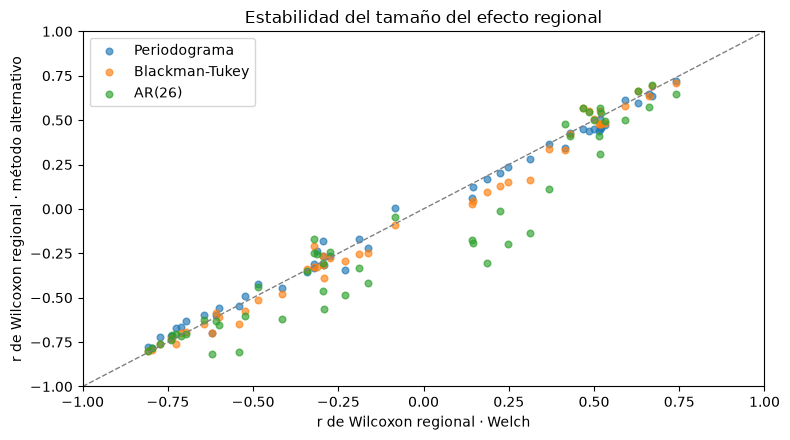

In [7]:
ref = wil4[wil4.metodo == 'Welch'][['medida','region','mediana_dif','r','signif']].rename(
    columns={'mediana_dif':'mediana_welch', 'r':'r_welch', 'signif':'sig_welch'})
comparacion = wil4.merge(ref, on=['medida','region'], validate='many_to_one')
comparacion['delta_mediana_vs_welch'] = comparacion.mediana_dif - comparacion.mediana_welch
comparacion['delta_r_vs_welch'] = comparacion.r - comparacion.r_welch
comparacion['misma_direccion'] = np.sign(comparacion.mediana_dif) == np.sign(comparacion.mediana_welch)
comparacion['misma_decision_FDR'] = comparacion.signif == comparacion.sig_welch
res_estabilidad = comparacion.groupby('metodo').agg(
    concordancia_direccion=('misma_direccion','mean'),
    concordancia_FDR=('misma_decision_FDR','mean'),
    mediana_abs_delta_r=('delta_r_vs_welch',lambda a: np.median(np.abs(a)))).reindex(list(ESTIMADORES))
display(res_estabilidad.round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
for metodo in ESTIMADORES:
    if metodo == 'Welch':
        continue
    d = comparacion[comparacion.metodo == metodo]
    ax.scatter(d.r_welch, d.r, label=metodo, alpha=0.65, s=23)
ax.plot([-1, 1], [-1, 1], '--', color='gray', linewidth=1)
ax.set(xlabel='r de Wilcoxon regional · Welch', ylabel='r de Wilcoxon regional · método alternativo',
       title='Estabilidad del tamaño del efecto regional', xlim=(-1,1), ylim=(-1,1))
ax.legend()
plt.tight_layout()

# La comparación G/B se hace también sobre sus decisiones de significancia.
ref_g = mw4[mw4.metodo == 'Welch'][['medida','region','r','signif']].rename(
    columns={'r':'r_welch', 'signif':'sig_welch'})
comparacion_g = mw4.merge(ref_g, on=['medida','region'])
comparacion_g['misma_decision_FDR'] = comparacion_g.signif == comparacion_g.sig_welch
comparacion_g['delta_r_vs_welch'] = comparacion_g.r - comparacion_g.r_welch
display(comparacion_g.groupby('metodo').agg(concordancia_FDR=('misma_decision_FDR','mean'),
                mediana_abs_delta_r=('delta_r_vs_welch',lambda x: np.median(np.abs(x)))).round(3))

## 6. Auditoría frente a los CSV estadísticos del Módulo 3 (si están disponibles)

Como el Módulo 3 se ejecutó con el archivo `modulo2_potencias.csv`, sus estadísticas deben reproducirse con **Welch**. Si se proporcionan los dos CSV opcionales, se cuantifica la diferencia y se advierte sobre cualquier discrepancia. Si no están disponibles, la comparación del apartado 2 sí permite corroborar las potencias de origen, pero las pruebas regionales no se contrastan directamente.

In [8]:
for archivo, tabla in [('modulo3_wilcoxon_regiones.csv', wil4), ('modulo3_mannwhitney.csv', mw4)]:
    if not Path(archivo).is_file():
        print(archivo, ': no cargado; verificación estadística externa pendiente.')
        continue
    original = pd.read_csv(archivo)
    actual = tabla[tabla.metodo == 'Welch']
    unidos = actual.merge(original, on=['medida','region'], validate='one_to_one',suffixes=('_m4','_m3'))
    assert len(unidos) == 50, 'Faltan filas para comparar en ' + archivo
    for campo in ('p', 'r', 'q'):
        mayor = np.max(np.abs(unidos[campo+'_m4'] - unidos[campo+'_m3']))
        print(archivo, '| máxima diferencia',campo,'=',f'{mayor:.3g}')
        if mayor > 1e-7:
            print('ADVERTENCIA: diferencia estadística entre módulos. Revisar antes de interpretar.')

modulo3_wilcoxon_regiones.csv | máxima diferencia p = 0
modulo3_wilcoxon_regiones.csv | máxima diferencia r = 0
modulo3_wilcoxon_regiones.csv | máxima diferencia q = 5.55e-17
modulo3_mannwhitney.csv | máxima diferencia p = 0
modulo3_mannwhitney.csv | máxima diferencia r = 0
modulo3_mannwhitney.csv | máxima diferencia q = 1.11e-16


## 7. Controles de robustez de decisiones de procesamiento

**7.1. Marcas exploratorias:** se recomputa **Welch con todas las épocas** y se contrasta con la referencia que excluye las marcadas. Se evalúan cambios en dirección, mediana y decisiones FDR, sin declarar que una de las dos opciones sea una corrección de artefactos validada.

**7.2. Denominador de potencia relativa:** se recalculan las cuatro bandas relativas por región con la normalización de **0,5–45 Hz** comprometida en el anteproyecto. Esto no requiere reestimar la PSD: `total_0p5_45` se almacenó junto con la potencia por banda. Se compara con la normalización utilizada en el Módulo 3. Los 50 tests conservan la misma estructura.

**7.3. Duración de época:** el anteproyecto solicita valorar la influencia de la segmentación. Se recompone el registro completo de 60 s por condición y se divide en épocas **2, 4 y 10 segundos** con Welch de ventana fija de 2 s, usando **todas las muestras**, porque las marcas del Módulo 1 corresponden exclusivamente a épocas de 4 s. Este control es descriptivo y compara la estimación de potencias regionales sin confundir segmentos de distintas duraciones con muestras independientes.

In [9]:
# 7.1 y 7.2: pruebas regionales sobre Welch; misma población y familia FDR.
welch_todas = tabla_estimadores(excluir_atipicas=False).query("metodo == 'Welch'").copy()
camb_todas = construir_cambios(welch_todas)
# Para reutilizar pruebas_regionales, ampliar temporalmente solo la lista de métodos.
# Se reutiliza la misma función estadística que para los cuatro estimadores.
w_ref = wil4[wil4.metodo == 'Welch']

def comparar_robustez(otros, titulo, medidas=MEDIDAS):
    base = w_ref[w_ref.medida.isin(medidas)][['medida','region','mediana_dif','r','signif']]
    o = otros[otros.medida.isin(medidas)][['medida','region','mediana_dif','r','signif']]
    junto = base.merge(o, on=['medida','region'], suffixes=('_ref','_otro'))
    print(titulo, '| pruebas:', len(junto),
          '| cambios de dirección:', int(np.sum(np.sign(junto.mediana_dif_ref) != np.sign(junto.mediana_dif_otro))),
          '| cambios de decisión FDR:', int(np.sum(junto.signif_ref != junto.signif_otro)),
          '| mediana |Δr|:',round(np.median(abs(junto.r_ref-junto.r_otro)), 3))
    return junto

w_todas, _ = pruebas_regionales(camb_todas)
control_epocas = comparar_robustez(w_todas, 'Welch incluyendo épocas marcadas')

camb_45 = construir_cambios(pot4[pot4.metodo == 'Welch'], denom_45=True)
w_45, _ = pruebas_regionales(camb_45)
control_denominador = comparar_robustez(w_45, 'Denominador 0,5-45 Hz', [f'rel_{b}' for b in BANDAS])

Welch incluyendo épocas marcadas | pruebas: 50 | cambios de dirección: 2 | cambios de decisión FDR: 3 | mediana |Δr|: 0.042
Denominador 0,5-45 Hz | pruebas: 20 | cambios de dirección: 0 | cambios de decisión FDR: 0 | mediana |Δr|: 0.014


In [10]:
def potencias_por_duracion(duracion):
    n = int(duracion * FS)
    salida = []
    for s in SUJETOS:
        for c in CONDICIONES:
            # [15 x 19 x 2000] -> [19 x 30000] en orden cronológico.
            continuo = EPOCAS[s, c].transpose(1,0,2).reshape(19, -1)
            assert continuo.shape[-1] % n == 0
            ep = continuo.reshape(19, -1, n).transpose(1,0,2)
            f, S = welch(ep)
            Sm = S.mean(axis=0)
            for banda, (f1,f2) in BANDAS.items():
                vals = integrar(f, Sm, f1,f2)
                for canal, potencia in zip(CANALES, vals):
                    salida.append((s,c,canal,banda,float(potencia)))
    return pd.DataFrame(salida, columns=['sujeto','condicion','canal','banda','potencia'])

# Un único cálculo de Welch con todas las épocas ya está disponible para 4 s.
tablas_dur = []
for dur in (2, 4, 10):
    t = (welch_todas[['sujeto','condicion','canal','banda','potencia']].copy()
         if dur == 4 else potencias_por_duracion(dur))
    t['duracion_s'] = dur
    tablas_dur.append(t)
duraciones = pd.concat(tablas_dur, ignore_index=True)
# Comparación sin pseudorreplicación: mediana de la potencia absoluta por banda entre sujetos,
# calculada sobre 19 canales solo como resumen descriptivo.
res_dur = (duraciones.groupby(['duracion_s','sujeto','condicion','banda']).potencia.mean().reset_index()
           .groupby(['duracion_s','condicion','banda']).potencia.median().unstack('duracion_s'))
display(res_dur.round(3))
print('Los cambios por duración pueden reflejar el efecto de las fronteras de las ventanas Welch;')
print('no constituyen pruebas independientes ni una selección optimizada de épocas.')

duracion_s           2       4       10
condicion banda                        
reposo    alfa   29.040  28.550  28.311
          beta   10.720  10.668  10.819
          delta  45.459  45.373  45.916
          theta  14.311  14.259  14.061
tarea     alfa   17.462  17.575  17.914
          beta    9.238   9.226   9.285
          delta  48.662  48.480  49.904
          theta  13.134  13.264  13.370

Los cambios por duración pueden reflejar el efecto de las fronteras de las ventanas Welch;
no constituyen pruebas independientes ni una selección optimizada de épocas.


## 8. Sensibilidad al filtrado adicional

Se reconstruyen los **60 s consecutivos** de cada registro a partir de las 15 épocas de 4 s. Se aplican el **FIR Kaiser** (60 dB, transición de 0,5 Hz, pasabanda 0,5–45 Hz, convolución centrada) y el **IIR Butterworth de orden 4** (0,5–45 Hz, secciones SOS, aplicación bidireccional), exactamente como en el Módulo 1. Luego se segmenta nuevamente en 15 épocas de 4 s, conservando las marcas exploratorias originales para permitir la comparación. Se estima la PSD con Welch y se repiten las 50 pruebas regionales pareadas y las 50 pruebas entre grupos.

El control sin filtrado adicional usa las potencias Welch ya verificadas contra el Módulo 2. Los resultados evalúan la **sensibilidad de las conclusiones**, no una mejora demostrada en la calidad de los registros. Los posibles efectos de borde del filtrado se consideran una limitación.

FIR: 3627 coeficientes | IIR: 8 polos


,Wilcoxon_signif,concordancia_direccion,concordancia_FDR,mediana_abs_delta_r,Mann_Whitney_signif
metodo,,,,,
FIR Kaiser,31,1.0,1.0,0.000,0
IIR Butterworth,31,1.0,1.0,0.003,0
Sin filtrado adicional,31,1.0,1.0,0.000,0


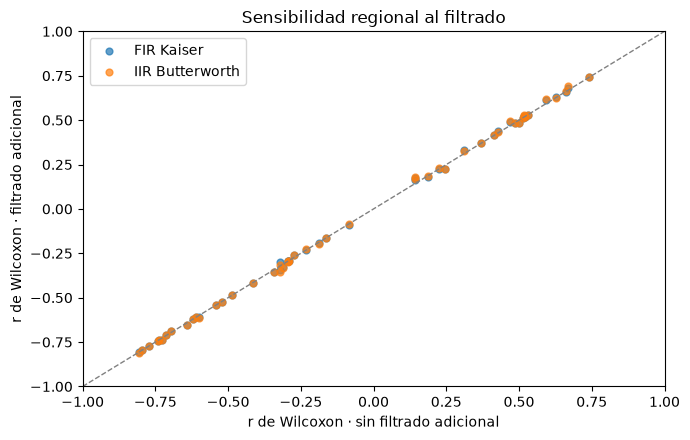

In [11]:
# Misma implementación y parámetros de los filtros del Módulo 1.
def filtro_fir(f1=0.5, f2=45, fs=500, aten_dB=60, transicion_hz=0.5):
    n, beta = signal.kaiserord(aten_dB, transicion_hz / (fs / 2))
    n += 1 - n % 2  # N impar, retardo entero
    return signal.firwin(n, [f1, f2], window=('kaiser', beta), pass_zero=False, fs=fs)

def filtro_iir(f1=0.5, f2=45, fs=500, orden=4):
    return signal.butter(orden, [f1, f2], btype='bandpass', fs=fs, output='sos')

fir, sos = filtro_fir(fs=FS), filtro_iir(fs=FS)
print('FIR:', len(fir), 'coeficientes | IIR:', 2 * len(sos), 'polos')

filas_filtros = []
for s in SUJETOS:
    for c in CONDICIONES:
        continuo = EPOCAS[s, c].transpose(1, 0, 2).reshape(len(CANALES), -1)
        # Filtrar el segmento completo evita reiniciar cada época de 4 s.
        versiones = {
            'FIR Kaiser': signal.oaconvolve(continuo, fir[None], mode='same', axes=-1),
            'IIR Butterworth': signal.sosfiltfilt(sos, continuo, axis=-1)
        }
        for filtro, datos in versiones.items():
            ep = datos.reshape(len(CANALES), 15, 2000).transpose(1, 0, 2)
            ep = ep[~ATIPICAS[s, c]]
            f, S = welch(ep)
            Sm = S.mean(axis=0)
            vals = {b: integrar(f, Sm, *lim) for b, lim in BANDAS.items()}
            tot45 = integrar(f, Sm, 0.5, 45)
            for j, canal in enumerate(CANALES):
                for banda in BANDAS:
                    filas_filtros.append((s, c, canal, filtro, banda,
                                         float(vals[banda][j]), float(tot45[j])))

pot_filtros = pd.DataFrame(filas_filtros, columns=pot4.drop(columns='potencia_rel').columns)
assert np.isfinite(pot_filtros[['potencia','total_0p5_45']]).all().all()
assert (pot_filtros[['potencia','total_0p5_45']] > 0).all().all()
base_filtro = pot4[pot4.metodo == 'Welch'].drop(columns='potencia_rel').copy()
base_filtro['metodo'] = 'Sin filtrado adicional'
pot_filtros = pd.concat([base_filtro, pot_filtros], ignore_index=True)
cambios_filtros = construir_cambios(pot_filtros)
wil_filtros, mw_filtros = pruebas_regionales(cambios_filtros)

ref_filtro = wil_filtros[wil_filtros.metodo == 'Sin filtrado adicional'][
    ['medida','region','mediana_dif','r','signif']].rename(
        columns={'mediana_dif':'mediana_ref','r':'r_ref','signif':'signif_ref'})
comp_filtros = wil_filtros.merge(ref_filtro, on=['medida','region'], validate='many_to_one')
comp_filtros['misma_direccion'] = np.sign(comp_filtros.mediana_dif) == np.sign(comp_filtros.mediana_ref)
comp_filtros['misma_decision_FDR'] = comp_filtros.signif == comp_filtros.signif_ref
comp_filtros['delta_r'] = comp_filtros.r - comp_filtros.r_ref
resumen_filtros = comp_filtros.groupby('metodo').agg(
    Wilcoxon_signif=('signif','sum'),
    concordancia_direccion=('misma_direccion','mean'),
    concordancia_FDR=('misma_decision_FDR','mean'),
    mediana_abs_delta_r=('delta_r',lambda x: np.median(np.abs(x))))
resumen_filtros['Mann_Whitney_signif'] = mw_filtros.groupby('metodo').signif.sum()
display(resumen_filtros.round(3))

fig, ax = plt.subplots(figsize=(7, 4.5))
for filtro in ['FIR Kaiser', 'IIR Butterworth']:
    parte = comp_filtros[comp_filtros.metodo == filtro]
    ax.scatter(parte.r_ref, parte.r, s=24, alpha=0.7, label=filtro)
ax.plot([-1,1],[-1,1],ls='--',color='gray',lw=1)
ax.set(xlim=(-1,1),ylim=(-1,1),xlabel='r de Wilcoxon · sin filtrado adicional',
       ylabel='r de Wilcoxon · filtrado adicional',
       title='Sensibilidad regional al filtrado')
ax.legend()
plt.tight_layout()

## 9. Exportación y síntesis de resultados

Se exportan las potencias, los cambios regionales, las pruebas estadísticas y las comparaciones de sensibilidad. Las tablas permiten identificar por separado cambios de magnitud, dirección y decisión FDR. Las interpretaciones se basan en **un sujeto por observación regional**, y no implican equivalencia estadística entre estimadores.

In [12]:
archivos = {
    'modulo4_potencias_metodos.csv': pot4,
    'modulo4_potencia_relativa_resumen.csv': tabla_bandas.reset_index(),
    'modulo4_cambios_regionales.csv': cambios,
    'modulo4_wilcoxon_metodos.csv': wil4,
    'modulo4_mannwhitney_metodos.csv': mw4,
    'modulo4_comparacion_welch.csv': comparacion,
    'modulo4_comparacion_grupos_welch.csv': comparacion_g,
    'modulo4_control_epocas.csv': control_epocas,
    'modulo4_control_denominador.csv': control_denominador,
    'modulo4_control_duracion.csv': duraciones,
    'modulo4_potencias_filtros.csv': pot_filtros,
    'modulo4_wilcoxon_filtros.csv': wil_filtros,
    'modulo4_mannwhitney_filtros.csv': mw_filtros,
    'modulo4_comparacion_filtros.csv': comp_filtros,
}
for nombre, tabla in archivos.items():
    tabla.to_csv(nombre, index=False)
print('Archivos guardados:', len(archivos))

print('Wilcoxon y Mann–Whitney: cantidad de pruebas significativas (q < 0,05):')
display(resumen)
print('Sensibilidad al estimador (frente a Welch):')
display(res_estabilidad.round(3))
print('Sensibilidad al filtrado (frente a sin filtrado adicional):')
display(resumen_filtros.round(3))
print('Épocas marcadas: cambios de decisión FDR:',
      int((control_epocas.signif_ref != control_epocas.signif_otro).sum()), '/ 50')
print('Denominador 0,5–45 Hz: cambios de decisión FDR:',
      int((control_denominador.signif_ref != control_denominador.signif_otro).sum()), '/ 20')

Archivos guardados: 14
Wilcoxon y Mann–Whitney: cantidad de pruebas significativas (q < 0,05):


,Wilcoxon_signif,Mann_Whitney_signif
metodo,,
Welch,31,0
Periodograma,30,0
Blackman-Tukey,30,0
AR(26),34,0


Sensibilidad al estimador (frente a Welch):


,concordancia_direccion,concordancia_FDR,mediana_abs_delta_r
metodo,,,
Welch,1.00,1.00,0.000
Periodograma,1.00,0.98,0.030
Blackman-Tukey,0.96,0.98,0.033
AR(26),0.88,0.90,0.062


Sensibilidad al filtrado (frente a sin filtrado adicional):


,Wilcoxon_signif,concordancia_direccion,concordancia_FDR,mediana_abs_delta_r,Mann_Whitney_signif
metodo,,,,,
FIR Kaiser,31,1.0,1.0,0.000,0
IIR Butterworth,31,1.0,1.0,0.003,0
Sin filtrado adicional,31,1.0,1.0,0.000,0


Épocas marcadas: cambios de decisión FDR: 3 / 50
Denominador 0,5–45 Hz: cambios de decisión FDR: 0 / 20


In [13]:
from IPython.display import Markdown

# Síntesis redactada a partir de los resultados reales de esta ejecución.
texto = ['### Síntesis cuantitativa de la ejecución']
for metodo in ESTIMADORES:
    fila = res_estabilidad.loc[metodo]
    w = int(resumen.loc[metodo, 'Wilcoxon_signif'])
    m = int(resumen.loc[metodo, 'Mann_Whitney_signif'])
    texto.append(f'- **{metodo}:** {w}/50 contrastes regionales Wilcoxon y {m}/50 Mann–Whitney '
                 f'con q < 0,05; concordancia con Welch: {fila.concordancia_direccion:.0%} en dirección '
                 f'y {fila.concordancia_FDR:.0%} en decisión FDR.')
for filtro in ('FIR Kaiser', 'IIR Butterworth'):
    fila = resumen_filtros.loc[filtro]
    texto.append(f'- **{filtro}:** {int(fila.Wilcoxon_signif)}/50 Wilcoxon significativos, '
                 f'{fila.concordancia_direccion:.0%} de concordancia de dirección y '
                 f'{fila.concordancia_FDR:.0%} de concordancia FDR frente a sin filtrado adicional.')
texto.append('- **Épocas marcadas:** '
             f'{int((control_epocas.signif_ref != control_epocas.signif_otro).sum())}/50 decisiones FDR modificadas.')
texto.append('- **Denominador 0,5–45 Hz:** '
             f'{int((control_denominador.signif_ref != control_denominador.signif_otro).sum())}/20 decisiones FDR modificadas.')
display(Markdown('\n'.join(texto)))

### Síntesis cuantitativa de la ejecución
- **Welch:** 31/50 contrastes regionales Wilcoxon y 0/50 Mann–Whitney con q < 0,05; concordancia con Welch: 100% en dirección y 100% en decisión FDR.
- **Periodograma:** 30/50 contrastes regionales Wilcoxon y 0/50 Mann–Whitney con q < 0,05; concordancia con Welch: 100% en dirección y 98% en decisión FDR.
- **Blackman-Tukey:** 30/50 contrastes regionales Wilcoxon y 0/50 Mann–Whitney con q < 0,05; concordancia con Welch: 96% en dirección y 98% en decisión FDR.
- **AR(26):** 34/50 contrastes regionales Wilcoxon y 0/50 Mann–Whitney con q < 0,05; concordancia con Welch: 88% en dirección y 90% en decisión FDR.
- **FIR Kaiser:** 31/50 Wilcoxon significativos, 100% de concordancia de dirección y 100% de concordancia FDR frente a sin filtrado adicional.
- **IIR Butterworth:** 31/50 Wilcoxon significativos, 100% de concordancia de dirección y 100% de concordancia FDR frente a sin filtrado adicional.
- **Épocas marcadas:** 3/50 decisiones FDR modificadas.
- **Denominador 0,5–45 Hz:** 0/20 decisiones FDR modificadas.

## 10. Conclusiones del Módulo 4

- **Estimadores espectrales.** La disminución de la potencia alfa y el aumento del índice θ/α constituyen los efectos más consistentes entre métodos. Con Welch se identificaron 31/50 comparaciones regionales significativas (Wilcoxon), frente a 30/50 con el periodograma y Blackman-Tukey, y 34/50 con AR(26). Respecto de Welch, el periodograma conservó el 100 % de las direcciones y el 98 % de las decisiones FDR; Blackman-Tukey, el 96 % y el 98 %; y AR(26), el 88 % y el 90 %, respectivamente. Por lo tanto, el modelo AR presentó la mayor sensibilidad al cambio de estimador.
- **Filtrado adicional.** Los filtros FIR Kaiser e IIR Butterworth conservaron las 31/50 comparaciones Wilcoxon significativas de Welch sin filtrado adicional, con un 100 % de concordancia tanto en la dirección de los cambios como en las decisiones tras la corrección FDR. En estas condiciones, un segundo filtrado no modificó las conclusiones estadísticas regionales.
- **Otras decisiones metodológicas.** Utilizar 0,5–45 Hz en lugar de 0,5–30 Hz como denominador de la potencia relativa no modificó ninguna de las 20 decisiones FDR evaluadas. En cambio, incluir las épocas marcadas por varianza elevada modificó 3 de 50 decisiones FDR. Estas marcas corresponden a un criterio exploratorio y no constituyen una detección validada de artefactos.
- **Desempeño y alcance.** Ninguno de los cuatro estimadores ni de las tres variantes de filtrado identificó diferencias significativas entre los grupos de buen y bajo desempeño mediante Mann-Whitney. La ausencia de significancia debe interpretarse considerando el tamaño desigual de los grupos, y no demuestra ausencia de efecto.

**Conclusión general.** La elección del estimador puede modificar la magnitud y la significancia de algunos resultados, especialmente con AR, pero los efectos predominantes asociados a alfa y θ/α se mantienen en términos generales. El filtrado adicional no modificó las decisiones estadísticas en los contrastes evaluados. En conjunto, estos resultados respaldan la estabilidad de las conclusiones principales frente a las decisiones metodológicas analizadas, sin implicar equivalencia completa entre técnicas.